# Phase 2e: Baseline IDS - K-Means (with supervised labelling)
**Adversarial ML for Intrusion Detection Systems (CICIDS2017)**

K-Means is unsupervised, so it is turned into a classifier the same way as in the reference paper:
1. Cluster the **training** data into K clusters.
2. Label each cluster with the **majority class** of the training samples inside it.
3. Classify a new flow by the label of its **nearest cluster centre**.

Trains on the **balanced** training set and evaluates on the **untouched** validation and test sets.

## Step 0: Imports and settings

In [1]:
import os, json, time
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score,
                             roc_curve, classification_report)

DATA_DIR = "data/processed"
MODEL_DIR = "models"
RESULT_DIR = "results"
N_CLUSTERS = 20          # number of clusters (try 10, 20, 50 in the sweep below)
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

needed = ["X_train_bal.npy", "y_train_bal_binary.npy", "X_val.npy", "y_val_binary.npy",
          "X_test.npy", "y_test_binary.npy"]
missing = [f for f in needed if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    raise FileNotFoundError(f"Missing in '{os.path.abspath(DATA_DIR)}': {missing}. "
                            "Run Phase 1 and Phase 1b, or fix DATA_DIR.")
print("Setup done, all data files found")

Setup done, all data files found


## Step 1: Load data

In [2]:
X_train = np.load(f"{DATA_DIR}/X_train_bal.npy")
y_train = np.load(f"{DATA_DIR}/y_train_bal_binary.npy")
X_val   = np.load(f"{DATA_DIR}/X_val.npy");  y_val  = np.load(f"{DATA_DIR}/y_val_binary.npy")
X_test  = np.load(f"{DATA_DIR}/X_test.npy"); y_test = np.load(f"{DATA_DIR}/y_test_binary.npy")

for n, X, y in [("train (balanced)", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"{n:17s} X={X.shape}  attack ratio={y.mean():.3f}")

train (balanced)  X=(694088, 70)  attack ratio=0.712
val               X=(378120, 70)  attack ratio=0.169
test              X=(378120, 70)  attack ratio=0.169


## Step 2: Cluster the training data and label each cluster

In [3]:
def fit_kmeans_classifier(X, y, k, seed=42):
    km = KMeans(n_clusters=k, n_init=3, random_state=seed)
    clusters = km.fit_predict(X)
    # Fraction of attack samples in each cluster (used as an attack score)
    attack_frac = np.array([y[clusters == c].mean() if (clusters == c).any() else 0.0 for c in range(k)])
    cluster_label = (attack_frac >= 0.5).astype(int)      # majority vote
    return km, attack_frac, cluster_label

def predict_kmeans(km, attack_frac, cluster_label, X):
    c = km.predict(X)
    return cluster_label[c], attack_frac[c], c

t0 = time.time()
km, attack_frac, cluster_label = fit_kmeans_classifier(X_train, y_train, N_CLUSTERS)
train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

joblib.dump({"kmeans": km, "attack_frac": attack_frac, "cluster_label": cluster_label},
            f"{MODEL_DIR}/kmeans_baseline.joblib")

Training time: 41.2 s


['models/kmeans_baseline.joblib']

## Step 3: Cluster purity
Pure clusters (attack fraction near 0 or 1) mean the clustering separates benign and attack traffic well. Mixed clusters are where the classifier makes mistakes.

 Cluster      Size  Attack frac    Label
       0    11,863        0.886   Attack
       1   204,956        0.837   Attack
       2     3,894        0.941   Attack
       3    67,094        0.673   Attack
       4    20,004        1.000   Attack
       5    35,495        1.000   Attack
       6    84,075        0.001   Benign
       7    45,240        0.942   Attack
       8    11,931        0.224   Benign
       9    21,143        0.222   Benign
      10     4,881        0.793   Attack
      11     4,407        0.939   Attack
      12    18,468        0.691   Attack
      13    19,937        0.696   Attack
      14    22,577        0.566   Attack
      15    11,715        0.598   Attack
      16    68,794        0.991   Attack
      17    10,316        0.962   Attack
      18    19,458        1.000   Attack
      19     7,840        0.731   Attack


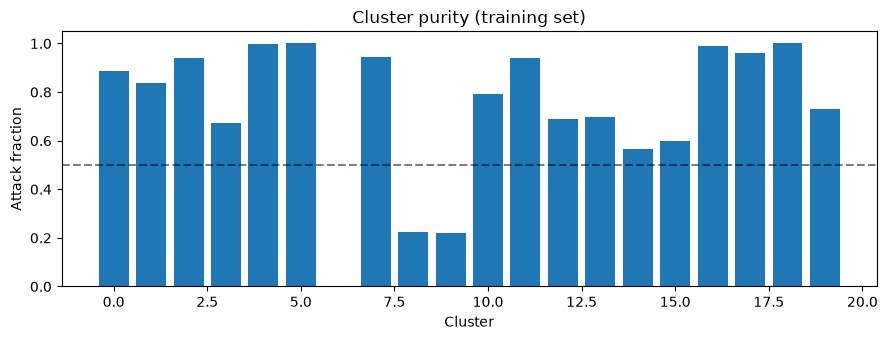

In [4]:
sizes = np.bincount(km.labels_, minlength=N_CLUSTERS)
print(f"{'Cluster':>8s} {'Size':>9s} {'Attack frac':>12s} {'Label':>8s}")
for c in range(N_CLUSTERS):
    print(f"{c:8d} {sizes[c]:9,d} {attack_frac[c]:12.3f} {'Attack' if cluster_label[c] else 'Benign':>8s}")

plt.figure(figsize=(9, 3.5))
plt.bar(range(N_CLUSTERS), attack_frac)
plt.axhline(0.5, color="k", ls="--", alpha=0.5)
plt.xlabel("Cluster"); plt.ylabel("Attack fraction"); plt.title("Cluster purity (training set)")
plt.tight_layout(); plt.show()

## Step 4: Evaluation function

In [6]:
def evaluate(X, y, name):
    y_pred, score, _ = predict_kmeans(km, attack_frac, cluster_label, X)
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    m = {
        "split": name,
        "accuracy":    accuracy_score(y, y_pred),
        "precision":   precision_score(y, y_pred, zero_division=0),
        "recall":      recall_score(y, y_pred),
        "f1":          f1_score(y, y_pred),
        "specificity": tn / (tn + fp),
        "fpr":         fp / (fp + tn),
        "fnr":         fn / (fn + tp),
        "roc_auc":     roc_auc_score(y, score),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    return m, y_pred, score

## Step 5: Results on validation and test sets

In [7]:
val_m,  val_pred,  val_score  = evaluate(X_val,  y_val,  "validation")
test_m, test_pred, test_score = evaluate(X_test, y_test, "test")

keys = ["accuracy", "precision", "recall", "f1", "specificity", "fpr", "fnr", "roc_auc"]
print(f"{'Metric':14s} {'Validation':>12s} {'Test':>12s}")
for k in keys:
    print(f"{k:14s} {val_m[k]:12.4f} {test_m[k]:12.4f}")

print("\nTest classification report:")
print(classification_report(y_test, test_pred, target_names=["Benign", "Attack"], digits=4))

Metric           Validation         Test
accuracy             0.6247       0.6249
precision            0.3103       0.3103
recall               0.9990       0.9988
f1                   0.4735       0.4735
specificity          0.5487       0.5490
fpr                  0.4513       0.4510
fnr                  0.0010       0.0012
roc_auc              0.9139       0.9138

Test classification report:
              precision    recall  f1-score   support

      Benign     0.9996    0.5490    0.7087    314259
      Attack     0.3103    0.9988    0.4735     63861

    accuracy                         0.6249    378120
   macro avg     0.6549    0.7739    0.5911    378120
weighted avg     0.8832    0.6249    0.6690    378120



## Step 6: Confusion matrix and ROC curve (test set)
The ROC curve has few points because the score is the attack fraction of the assigned cluster, so it can take at most K distinct values.

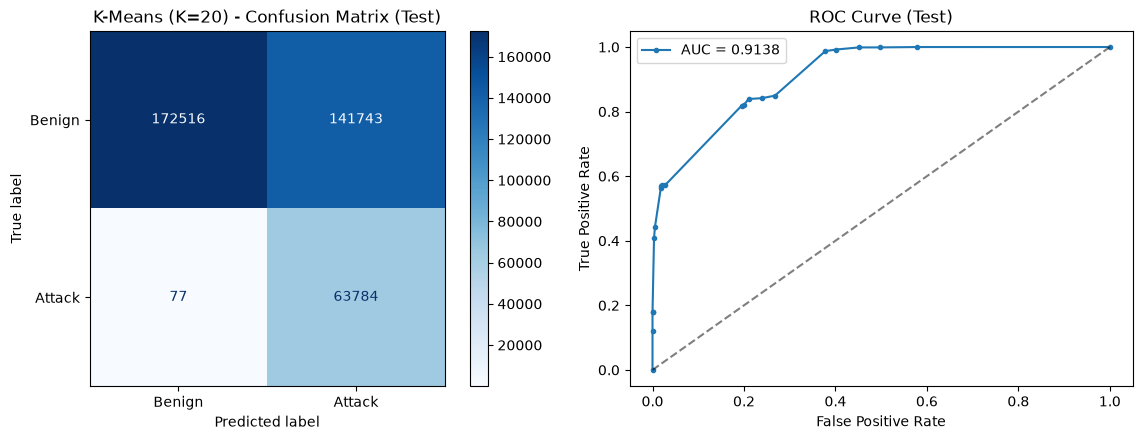

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, test_pred)
ConfusionMatrixDisplay(cm, display_labels=["Benign", "Attack"]).plot(ax=ax[0], cmap="Blues", values_format="d")
ax[0].set_title(f"K-Means (K={N_CLUSTERS}) - Confusion Matrix (Test)")

fpr, tpr, _ = roc_curve(y_test, test_score)
ax[1].plot(fpr, tpr, marker="o", ms=3, label=f"AUC = {test_m['roc_auc']:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("ROC Curve (Test)"); ax[1].legend()

plt.tight_layout()
plt.savefig(f"{RESULT_DIR}/kmeans_clean_cm_roc.png", dpi=150)
plt.show()

## Step 7: Save results

In [9]:
with open(f"{RESULT_DIR}/kmeans_clean_metrics.json", "w") as f:
    json.dump({"validation": val_m, "test": test_m, "train_time_s": train_time, "n_clusters": N_CLUSTERS}, f, indent=2)
print("Saved:", sorted(os.listdir(RESULT_DIR)))

Saved: ['decision_tree_clean_cm_roc.png', 'decision_tree_clean_metrics.json', 'decision_tree_feature_importance.png', 'kmeans_clean_cm_roc.png', 'kmeans_clean_metrics.json', 'logreg_clean_cm_roc.png', 'logreg_clean_metrics.json', 'svm_clean_cm_roc.png', 'svm_clean_metrics.json', 'xgboost_clean_cm_roc.png', 'xgboost_clean_metrics.json', 'xgboost_feature_importance.png']


## Step 8: Compare with the other models trained so far

In [10]:
models = {"LogReg": "logreg_clean_metrics.json", "LinearSVM": "svm_clean_metrics.json",
          "XGBoost": "xgboost_clean_metrics.json", "DecTree": "decision_tree_clean_metrics.json",
          "KMeans": "kmeans_clean_metrics.json"}
res = {}
for name, fn_ in models.items():
    p = os.path.join(RESULT_DIR, fn_)
    if os.path.exists(p):
        res[name] = json.load(open(p))["test"]

print(f"{'Metric':14s}" + "".join(f"{n:>11s}" for n in res))
for k in keys:
    print(f"{k:14s}" + "".join(f"{res[n][k]:11.4f}" for n in res))

Metric             LogReg  LinearSVM    XGBoost    DecTree     KMeans
accuracy           0.7908     0.7955     0.9988     0.9983     0.6249
precision          0.4464     0.4521     0.9931     0.9914     0.3103
recall             0.9951     0.9938     0.9999     0.9987     0.9988
f1                 0.6163     0.6215     0.9965     0.9950     0.4735
specificity        0.7493     0.7553     0.9986     0.9982     0.5490
fpr                0.2507     0.2447     0.0014     0.0018     0.4510
fnr                0.0049     0.0062     0.0001     0.0013     0.0012
roc_auc            0.9745     0.9759     1.0000     0.9986     0.9138


## Optional: choose K using the validation set
Set `RUN_K_SWEEP = True` to try several values of K (each fit takes a while). Pick K by validation F1, **not** by test results.

In [ ]:
RUN_K_SWEEP = False

if RUN_K_SWEEP:
    for k in [2, 10, 20, 50, 100]:
        km_k, af_k, cl_k = fit_kmeans_classifier(X_train, y_train, k)
        pred_k = cl_k[km_k.predict(X_val)]
        print(f"K={k:3d}  val F1={f1_score(y_val, pred_k):.4f}  val FNR={1 - recall_score(y_val, pred_k):.4f}")

## Notes for the report and Phase 3
- K-Means is distance-based and has no gradient, so FGSM/PGD cannot be applied to it directly. Use a **transfer attack** from a differentiable surrogate, or a black-box attack.
- An attacker only needs to push a malicious flow across the boundary into a benign-labelled cluster, which is why cluster purity (Step 3) is relevant to robustness.
- Unsupervised clustering usually scores below supervised models on this data. The reference paper reports K-Means as its weakest model, which is a useful point of comparison.